Iteration: 1 Best Fitness: 0.029232
Iteration: 2 Best Fitness: 0.029232
Iteration: 3 Best Fitness: 0.005594
Iteration: 4 Best Fitness: 0.005594
Iteration: 5 Best Fitness: 0.000352
Iteration: 6 Best Fitness: 9.9e-05
Iteration: 7 Best Fitness: 9.9e-05
Iteration: 8 Best Fitness: 8e-06
Iteration: 9 Best Fitness: 8e-06
Iteration: 10 Best Fitness: 6e-06
Iteration: 11 Best Fitness: 1e-06
Iteration: 12 Best Fitness: 1e-06
Iteration: 13 Best Fitness: 1e-06
Iteration: 14 Best Fitness: 0.0
Iteration: 15 Best Fitness: 0.0
Iteration: 16 Best Fitness: 0.0
Iteration: 17 Best Fitness: 0.0
Iteration: 18 Best Fitness: 0.0
Iteration: 19 Best Fitness: 0.0
Iteration: 20 Best Fitness: 0.0
Iteration: 21 Best Fitness: 0.0
Iteration: 22 Best Fitness: 0.0
Iteration: 23 Best Fitness: 0.0
Iteration: 24 Best Fitness: 0.0
Iteration: 25 Best Fitness: 0.0
Iteration: 26 Best Fitness: 0.0
Iteration: 27 Best Fitness: 0.0
Iteration: 28 Best Fitness: 0.0
Iteration: 29 Best Fitness: 0.0
Iteration: 30 Best Fitness: 0.0
Iter

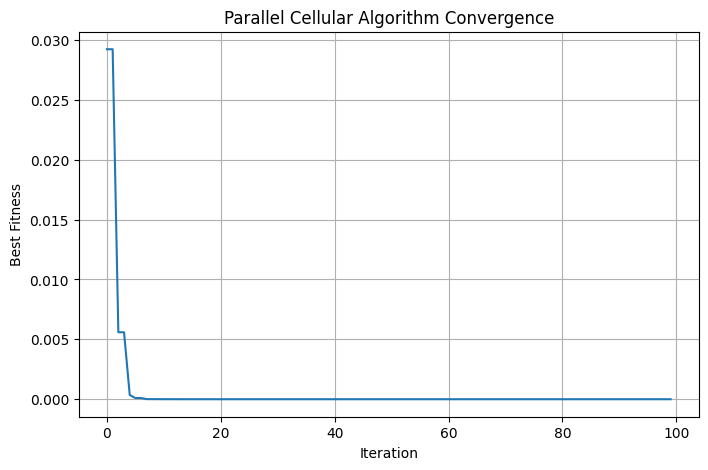

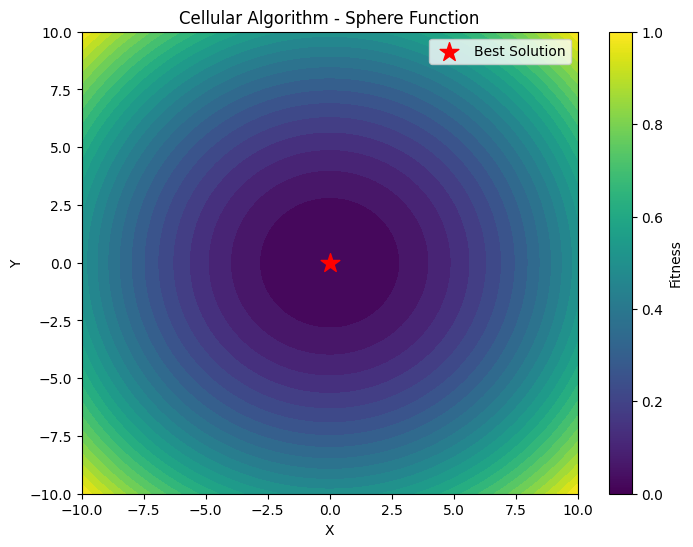

In [1]:

import numpy as np
import matplotlib.pyplot as plt

grid_size = 10
dimensions = 2
iterations = 100

lower_bound = -10
upper_bound = 10

crossover_rate = 0.8
mutation_rate = 0.1

grid = np.random.uniform(
    lower_bound,
    upper_bound,
    (grid_size, grid_size, dimensions)
)

def fitness(position):
    return np.sum(position ** 2)

def get_neighbors(i, j, population):
    neighbors = []

    for di in [-1, 0, 1]:
        for dj in [-1, 0, 1]:

            if di == 0 and dj == 0:
                continue

            ni = (i + di) % grid_size
            nj = (j + dj) % grid_size

            neighbors.append(population[ni, nj])

    return np.array(neighbors)

def tournament_selection(neighborhood):
    indices = np.random.choice(
        len(neighborhood), 2, replace=False
    )

    candidates = neighborhood[indices]

    scores = np.array([fitness(c) for c in candidates])

    return candidates[np.argmin(scores)].copy()

best_solution = grid[0, 0].copy()
best_fitness = fitness(best_solution)

convergence = []

for iteration in range(iterations):

    next_grid = grid.copy()

    for i in range(grid_size):
        for j in range(grid_size):

            neighborhood = get_neighbors(i, j, grid)

            parent1 = tournament_selection(neighborhood)
            parent2 = tournament_selection(neighborhood)

            if np.random.random() < crossover_rate:

                alpha = np.random.random(dimensions)

                child = (
                    alpha * parent1
                    + (1 - alpha) * parent2
                )

            else:
                child = parent1.copy()

            mutation = (
                np.random.random(dimensions) < mutation_rate
            )

            child[mutation] += np.random.normal(
                0, 1, np.sum(mutation)
            )

            child = np.clip(
                child, lower_bound, upper_bound
            )

            current_solution = grid[i, j]

            if fitness(child) < fitness(current_solution):
                next_grid[i, j] = child

            if fitness(child) < best_fitness:
                best_fitness = fitness(child)
                best_solution = child.copy()

    grid = next_grid

    convergence.append(best_fitness)

    print(
        "Iteration:", iteration + 1,
        "Best Fitness:", round(best_fitness, 6)
    )

print("Best Solution:", best_solution)
print("Minimum Function Value:", best_fitness)

plt.figure(figsize=(8, 5))
plt.plot(convergence)
plt.xlabel("Iteration")
plt.ylabel("Best Fitness")
plt.title("Parallel Cellular Algorithm Convergence")
plt.grid()
plt.show()

x = np.linspace(lower_bound, upper_bound, 100)
y = np.linspace(lower_bound, upper_bound, 100)

X, Y = np.meshgrid(x, y)
Z = X**2 + Y**2

plt.figure(figsize=(8, 6))

plt.contourf(X, Y, Z, levels=30, cmap='viridis')

plt.scatter(
    best_solution[0],
    best_solution[1],
    color='red',
    marker='*',
    s=200,
    label='Best Solution'
)

plt.xlabel("X")
plt.ylabel("Y")
plt.title("Cellular Algorithm - Sphere Function")
plt.legend()
plt.colorbar(label="Fitness")
plt.show()
